In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from olist.data import Olist
from olist.order import Order
from olist.seller import Seller
from olist.utils import it_costs, removal_scenarios, REVIEW_COSTS, SALES_FEE_RATE, SUBSCRIPTION_PER_MONTH, IT_ALPHA, IT_BETA

In [2]:
print("Varsayımlar")
print(f"  Satış komisyonu: teslim edilen siparişlerde ürün fiyatının %{SALES_FEE_RATE * 100:.0f}'i")
print(f"  Abonelik: satıcı başına ayda {SUBSCRIPTION_PER_MONTH} BRL")
print(f"  Yorum maliyeti (BRL): {REVIEW_COSTS}")
print(f"  IT maliyeti: {IT_ALPHA} * sqrt(n_sellers) + {IT_BETA} * sqrt(n_items)")
print()
print(f"Kontrol 1000 satıcı, 100 ürün: {it_costs(1000, 100):,.0f} BRL (beklenen 109,624)")
print(f"Kontrol 100 satıcı, 1000 ürün: {it_costs(100, 1000):,.0f} BRL (beklenen 62,507)")

Varsayımlar
  Satış komisyonu: teslim edilen siparişlerde ürün fiyatının %10'i
  Abonelik: satıcı başına ayda 80 BRL
  Yorum maliyeti (BRL): {1: 100, 2: 50, 3: 40, 4: 0, 5: 0}
  IT maliyeti: 3157.27 * sqrt(n_sellers) + 978.23 * sqrt(n_items)

Kontrol 1000 satıcı, 100 ürün: 109,624 BRL (beklenen 109,624)
Kontrol 100 satıcı, 1000 ürün: 62,507 BRL (beklenen 62,507)


In [3]:
data = Olist().get_data()
order = Order(data)

order_econ = order.get_order_economics()
print("Sipariş sayısı:", len(order_econ))
print(f"Toplam satış komisyonu: {order_econ['sales_fee'].sum():,.0f} BRL")
print(f"Toplam yorum maliyeti: {order_econ['cost_of_review'].sum():,.0f} BRL")
print(f"Sipariş başına ortalama komisyon: {order_econ['sales_fee'].mean():.2f} BRL | ortalama yorum maliyeti: {order_econ['cost_of_review'].mean():.2f} BRL")

order_econ.groupby(order_econ["review_score"].round()).agg(
    siparis=("order_id", "count"),
    ort_komisyon=("sales_fee", "mean"),
    ort_yorum_maliyeti=("cost_of_review", "mean"),
    toplam_yorum_maliyeti=("cost_of_review", "sum"),
).round(2)

Sipariş sayısı: 98666
Toplam satış komisyonu: 1,322,150 BRL
Toplam yorum maliyeti: 1,557,985 BRL
Sipariş başına ortalama komisyon: 13.40 BRL | ortalama yorum maliyeti: 15.79 BRL


,siparis,ort_komisyon,ort_yorum_maliyeti,toplam_yorum_maliyeti
review_score,,,,
1.0,10778,14.28,100.00,1077800.00
2.0,3104,13.67,50.13,155590.00
3.0,8084,12.48,40.02,323541.67
4.0,19066,13.13,0.06,1053.33
5.0,56885,13.42,0.00,0.00


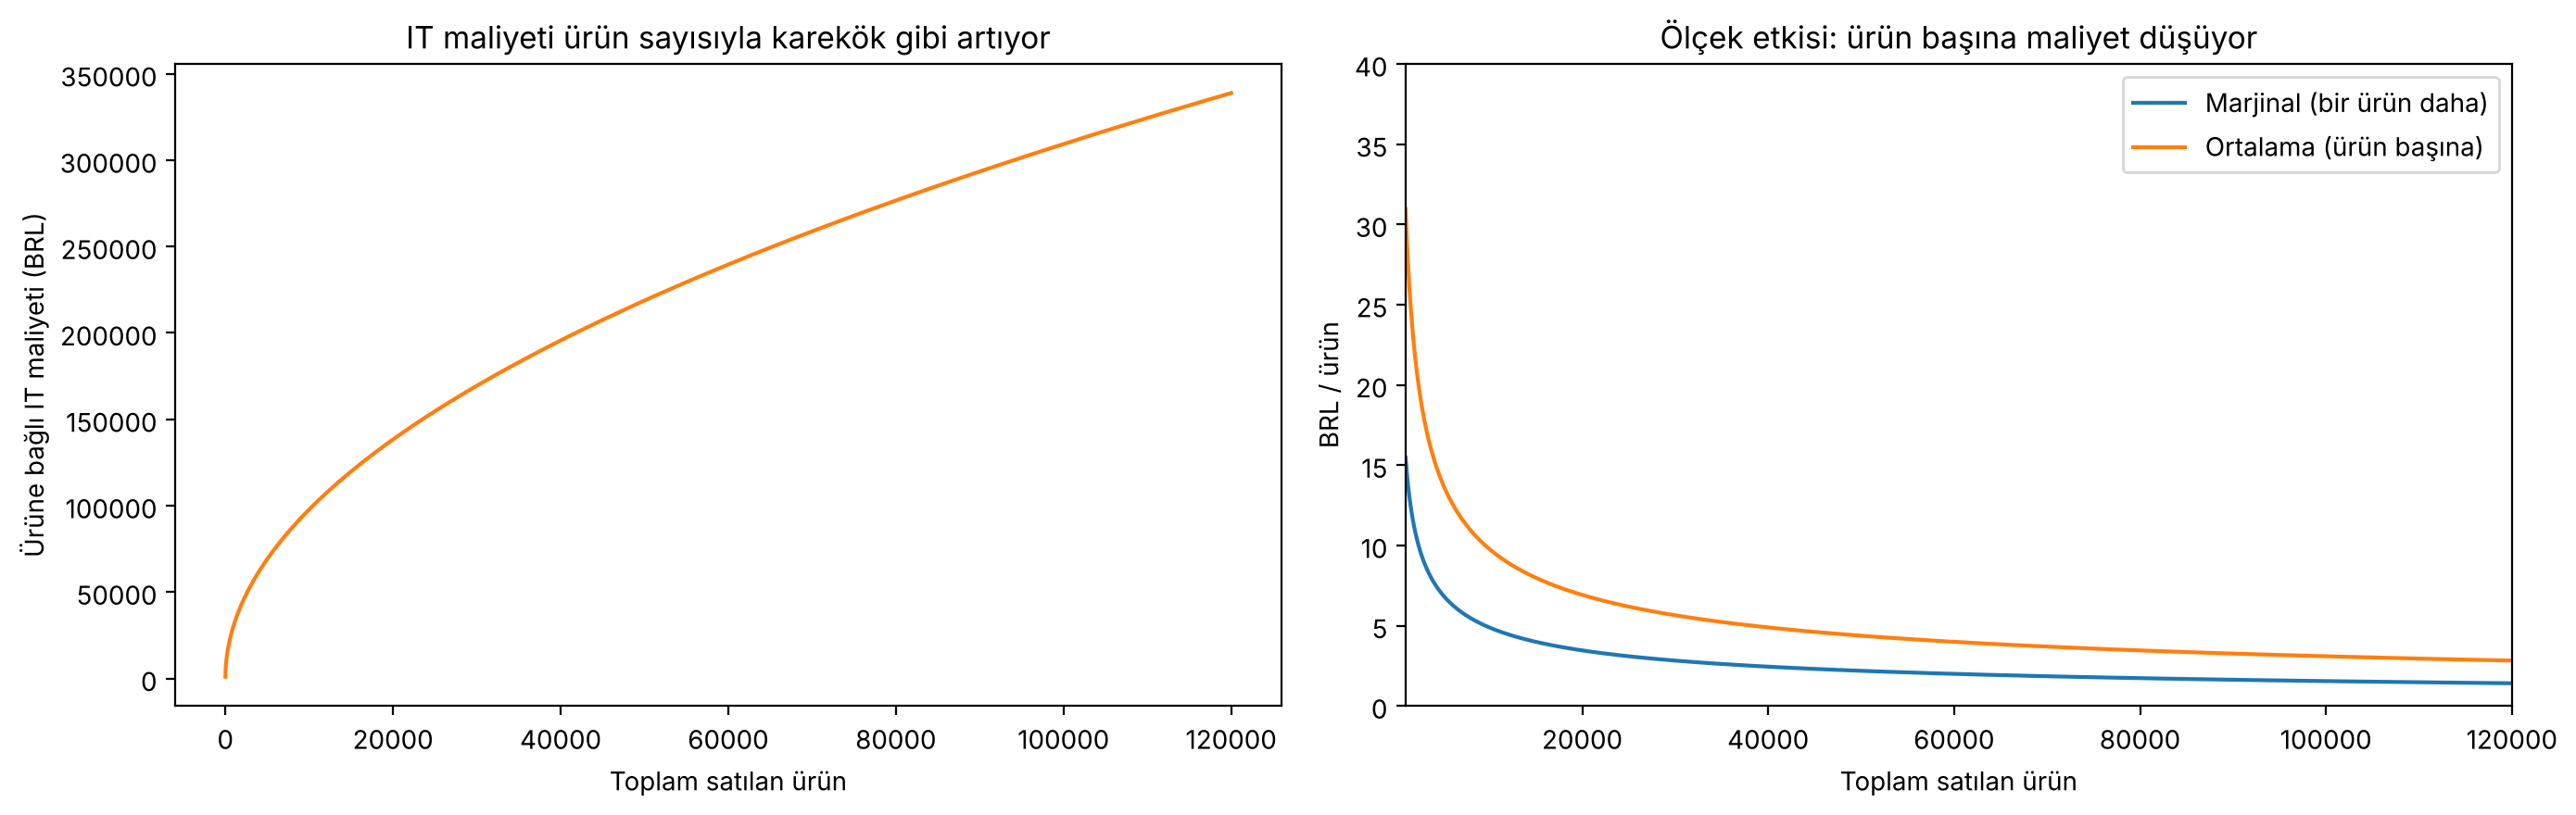

112.441 üründe ürün başına ortalama IT maliyeti: 2.92 BRL, marjinal: 1.46 BRL
2967 satıcıda satıcı başına ortalama IT maliyeti: 57.96 BRL, marjinal: 28.98 BRL


In [4]:
n_items_grid = np.arange(1, 120_001)
n_sellers_now = 2967

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(n_items_grid, IT_BETA * np.sqrt(n_items_grid), color="tab:orange")
axes[0].set_xlabel("Toplam satılan ürün")
axes[0].set_ylabel("Ürüne bağlı IT maliyeti (BRL)")
axes[0].set_title("IT maliyeti ürün sayısıyla karekök gibi artıyor")
axes[1].plot(n_items_grid, IT_BETA / (2 * np.sqrt(n_items_grid)), label="Marjinal (bir ürün daha)")
axes[1].plot(n_items_grid, IT_BETA / np.sqrt(n_items_grid), label="Ortalama (ürün başına)")
axes[1].set_xlim(1000, 120_000)
axes[1].set_ylim(0, 40)
axes[1].set_xlabel("Toplam satılan ürün")
axes[1].set_ylabel("BRL / ürün")
axes[1].set_title("Ölçek etkisi: ürün başına maliyet düşüyor")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"112.441 üründe ürün başına ortalama IT maliyeti: {IT_BETA / np.sqrt(112_441):.2f} BRL, marjinal: {IT_BETA / (2 * np.sqrt(112_441)):.2f} BRL")
print(f"2967 satıcıda satıcı başına ortalama IT maliyeti: {IT_ALPHA / np.sqrt(n_sellers_now):.2f} BRL, marjinal: {IT_ALPHA / (2 * np.sqrt(n_sellers_now)):.2f} BRL")

In [5]:
sellers = Seller(data).get_training_data()

print("sellers şekli:", sellers.shape)
print("Benzersiz seller_id:", sellers["seller_id"].is_unique, "| eksik değer:", int(sellers.isna().sum().sum()))
print("Medyan review_score:", round(sellers["review_score"].median(), 2))
print(f"Dağıtılan IT maliyeti: {sellers['operational_costs'].sum():,.0f} BRL | formülle: {it_costs(len(sellers), sellers['quantity'].sum()):,.0f} BRL")

economics = ["subscription_fees", "sales_fees", "revenues", "cost_of_reviews", "operational_costs", "net_contribution"]
pd.DataFrame({"toplam": sellers[economics].sum(), "medyan": sellers[economics].median()}).round(0)

sellers şekli: (2967, 23)
Benzersiz seller_id: True | eksik değer: 0
Medyan review_score: 4.21
Dağıtılan IT maliyeti: 499,999 BRL | formülle: 499,999 BRL


,toplam,medyan
subscription_fees,1451840.0,320.0
sales_fees,1321473.0,85.0
revenues,2773313.0,460.0
cost_of_reviews,1544195.0,100.0
operational_costs,499999.0,81.0
net_contribution,729119.0,161.0


In [6]:
print("Net katkısı negatif satıcı:", int((sellers["net_contribution"] < 0).sum()), "/", len(sellers))
print("IT öncesi kârı negatif satıcı:", int((sellers["profits"] < 0).sum()))

sellers[["months_on_olist", "n_orders", "quantity", "sales", "revenues", "revenue_per_month", "cost_of_reviews", "operational_costs", "net_contribution"]].describe().round(1)

Net katkısı negatif satıcı: 954 / 2967
IT öncesi kârı negatif satıcı: 359


,months_on_olist,n_orders,quantity,sales,revenues,revenue_per_month,cost_of_reviews,operational_costs,net_contribution
count,2967.0,2967.0,2967.0,2967.0,2967.0,2967.0,2967.0,2967.0,2967.0
mean,6.1,33.7,37.9,4568.9,934.7,120.0,520.5,168.5,245.7
std,6.1,107.2,121.5,14191.8,1639.8,127.3,1813.2,354.5,1377.9
min,0.0,1.0,1.0,6.5,0.6,0.6,0.0,60.9,-26833.5
25%,1.0,2.0,3.0,239.8,121.0,83.9,0.0,66.7,-45.0
50%,4.0,7.0,8.0,896.0,460.5,99.3,100.0,81.3,160.6
75%,10.0,23.0,26.0,3584.0,1188.6,130.0,350.0,133.8,563.8
max,23.0,1854.0,2033.0,229472.6,24138.8,1953.9,36757.5,5988.8,16330.0


In [7]:
cols = ["seller_id", "seller_state", "months_on_olist", "n_orders", "quantity", "review_score", "share_of_one_stars", "revenues", "cost_of_reviews", "operational_costs", "net_contribution"]
sellers.sort_values("net_contribution")[cols].head(10).round(2)

,seller_id,seller_state,months_on_olist,n_orders,quantity,review_score,share_of_one_stars,revenues,cost_of_reviews,operational_costs,net_contribution
769,6560211a19b47992c3666cc44a7e94c0,SP,19.0,1854,2033,3.94,0.13,13590.28,34435.00,5988.80,-26833.52
1357,cc419e0650a3c5ba77189a1882b7556a,SP,19.0,1706,1775,4.07,0.12,11629.10,28826.67,5236.14,-22433.71
2358,4a3ca9315b744ce9f8e9374361493884,SP,20.0,1806,1987,3.83,0.14,21288.21,36757.50,5854.61,-21323.89
945,ea8482cd71df3c1969d7b9473ff13abc,SP,12.0,1146,1203,4.00,0.11,4629.68,19675.00,3567.46,-18612.78
315,8b321bb669392f5163d04c59e235e066,SP,10.0,943,1018,4.07,0.12,2526.29,15123.33,3027.76,-15624.80
453,1f50f920176fa81dab994f9023523100,SP,17.0,1404,1931,4.13,0.11,12025.57,20930.68,5691.24,-14596.35
1132,7c67e1448b00f6e969d365cea6b010ab,SP,19.0,982,1364,3.49,0.20,20177.00,27843.93,4037.14,-11704.06
1213,d2374cbcbb3ca4ab1086534108cc3ab7,SP,19.0,524,631,3.76,0.14,3612.60,11260.03,1898.77,-9546.20
2023,cca3071e3e9bb7d12640c9fbe2301306,SP,23.0,712,830,3.84,0.15,8143.52,14176.67,2479.31,-8512.46
2687,1835b56ce799e6a4dc4eddc053f04066,SP,12.0,423,558,3.63,0.21,4260.53,10228.33,1685.81,-7653.61


In [8]:
scenarios = removal_scenarios(sellers, rank_col="net_contribution")
base = scenarios.loc[0]

best_n = int(scenarios["profit"].idxmax())
best_n_before_it = int(scenarios["profit_before_it"].idxmax())
last_positive = int(scenarios.loc[scenarios["profit"] > base["profit"], "n_removed"].max())

print(f"Bugünkü kâr (IT sonrası): {base['profit']:,.0f} BRL")
print(f"IT dahil optimum: {best_n} satıcı çıkar -> kâr {scenarios.loc[best_n, 'profit']:,.0f} BRL ({scenarios.loc[best_n, 'profit'] - base['profit']:+,.0f})")
print(f"IT hariç optimum: {best_n_before_it} satıcı çıkar -> IT öncesi kâr {scenarios.loc[best_n_before_it, 'profit_before_it'] - base['profit_before_it']:+,.0f} BRL")
print(f"Kâr artışı {last_positive} satıcıya kadar pozitif kalıyor")

Bugünkü kâr (IT sonrası): 729,119 BRL
IT dahil optimum: 840 satıcı çıkar -> kâr 1,105,406 BRL (+376,287)
IT hariç optimum: 383 satıcı çıkar -> IT öncesi kâr +269,270 BRL
Kâr artışı 2320 satıcıya kadar pozitif kalıyor


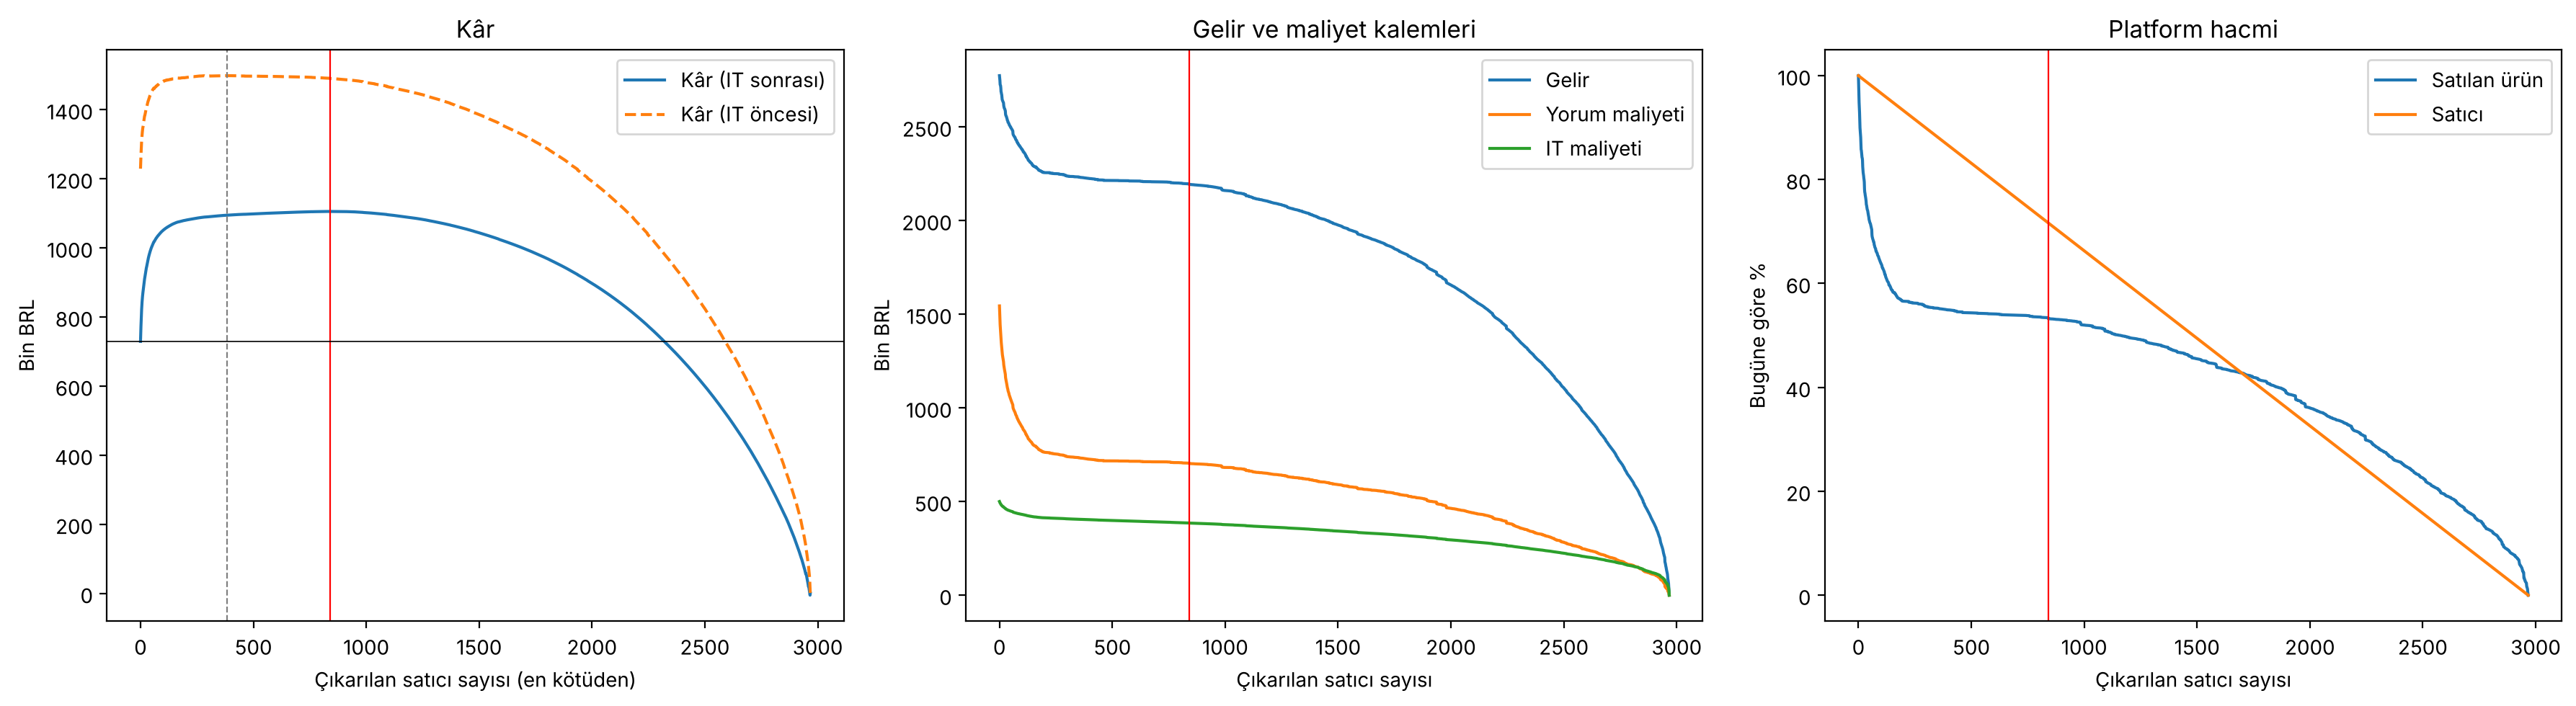

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(scenarios["n_removed"], scenarios["profit"] / 1e3, label="Kâr (IT sonrası)")
axes[0].plot(scenarios["n_removed"], scenarios["profit_before_it"] / 1e3, label="Kâr (IT öncesi)", linestyle="--")
axes[0].axvline(best_n, color="red", linewidth=0.8)
axes[0].axvline(best_n_before_it, color="gray", linewidth=0.8, linestyle="--")
axes[0].axhline(base["profit"] / 1e3, color="black", linewidth=0.6)
axes[0].set_xlabel("Çıkarılan satıcı sayısı (en kötüden)")
axes[0].set_ylabel("Bin BRL")
axes[0].set_title("Kâr")
axes[0].legend()

axes[1].plot(scenarios["n_removed"], scenarios["revenues"] / 1e3, label="Gelir")
axes[1].plot(scenarios["n_removed"], scenarios["cost_of_reviews"] / 1e3, label="Yorum maliyeti")
axes[1].plot(scenarios["n_removed"], scenarios["it_costs"] / 1e3, label="IT maliyeti")
axes[1].axvline(best_n, color="red", linewidth=0.8)
axes[1].set_xlabel("Çıkarılan satıcı sayısı")
axes[1].set_ylabel("Bin BRL")
axes[1].set_title("Gelir ve maliyet kalemleri")
axes[1].legend()

axes[2].plot(scenarios["n_removed"], scenarios["n_items"] / scenarios.loc[0, "n_items"] * 100, label="Satılan ürün")
axes[2].plot(scenarios["n_removed"], scenarios["n_sellers"] / scenarios.loc[0, "n_sellers"] * 100, label="Satıcı")
axes[2].axvline(best_n, color="red", linewidth=0.8)
axes[2].set_xlabel("Çıkarılan satıcı sayısı")
axes[2].set_ylabel("Bugüne göre %")
axes[2].set_title("Platform hacmi")
axes[2].legend()

plt.tight_layout()
plt.show()

In [10]:
def impact(n):
    row = scenarios.loc[n]
    return {
        "çıkarılan": n,
        "kâr": row["profit"],
        "kâr_değişimi": row["profit"] - base["profit"],
        "kâr_değişimi_%": (row["profit"] / base["profit"] - 1) * 100,
        "IT_öncesi_kâr": row["profit_before_it"],
        "gelir_kaybı_%": (1 - row["revenues"] / base["revenues"]) * 100,
        "yorum_maliyeti_azalışı": base["cost_of_reviews"] - row["cost_of_reviews"],
        "IT_tasarrufu": base["it_costs"] - row["it_costs"],
        "ürün_kaybı_%": (1 - row["n_items"] / base["n_items"]) * 100,
        "kalan_satıcı": row["n_sellers"],
    }

pd.DataFrame([impact(n) for n in [0, 18, 50, 100, best_n_before_it, best_n]]).round(1)

,çıkarılan,kâr,kâr_değişimi,kâr_değişimi_%,IT_öncesi_kâr,gelir_kaybı_%,yorum_maliyeti_azalışı,IT_tasarrufu,ürün_kaybı_%,kalan_satıcı
0,0,729118.7,0.0,0.0,1229118.0,0.0,0.0,0.0,0.0,2967.0
1,18,909880.3,180761.6,24.8,1381522.4,5.3,298424.6,28357.2,16.3,2949.0
2,50,1003526.6,274407.8,37.6,1452189.3,9.9,498075.6,51336.6,28.1,2917.0
3,100,1050685.8,321567.1,44.1,1481914.7,14.2,645748.4,68770.5,36.1,2867.0
4,383,1094576.2,365457.5,50.1,1498387.8,19.7,815659.8,96187.7,45.0,2584.0
5,840,1105405.8,376287.0,51.6,1490753.4,20.8,839384.8,114651.7,46.6,2127.0


In [11]:
ranking = sellers.sort_values("net_contribution")["seller_id"].tolist()
rank_map = {seller_id: i for i, seller_id in enumerate(ranking)}

gains = {}
for sub_rule in ["yuvarlanmış ay", "en az 1 ay"]:
    for factor in [0.5, 1.0, 1.5, 2.0]:
        variant = sellers.copy()
        months = variant["months_on_olist"] if sub_rule == "yuvarlanmış ay" else variant["months_on_olist"].clip(lower=1)
        variant["revenues"] = months * SUBSCRIPTION_PER_MONTH + variant["sales_fees"]
        variant["cost_of_reviews"] = variant["cost_of_reviews"] * factor
        variant["rank"] = variant["seller_id"].map(rank_map)
        sc = removal_scenarios(variant, rank_col="rank")
        gains[f"{sub_rule}, yorum x{factor}"] = sc["profit"] - sc.loc[0, "profit"]

gains = pd.DataFrame(gains)
worst_case = gains.min(axis=1)
robust_n = int(worst_case.idxmax())
robust_limit = int(worst_case[worst_case > 0].index.max())

print(f"Tüm senaryolarda en iyi kötü-durum kazancı: {robust_n} satıcı çıkar -> en kötü senaryoda {worst_case[robust_n]:+,.0f} BRL")
print(f"Kazanç tüm senaryolarda {robust_limit} satıcıya kadar pozitif kalıyor")
print()
summary = pd.DataFrame({
    "senaryo optimumu (N)": gains.idxmax(),
    "optimum kazanç": gains.max(),
    f"N={robust_n} kazancı": gains.loc[robust_n],
    f"N={best_n} kazancı": gains.loc[best_n],
})
summary.round(0)

Tüm senaryolarda en iyi kötü-durum kazancı: 18 satıcı çıkar -> en kötü senaryoda +31,549 BRL
Kazanç tüm senaryolarda 95 satıcıya kadar pozitif kalıyor



,senaryo optimumu (N),optimum kazanç,N=18 kazancı,N=840 kazancı
"yuvarlanmış ay, yorum x0.5",18,31549.0,31549.0,-43405.0
"yuvarlanmış ay, yorum x1.0",840,376287.0,180762.0,376287.0
"yuvarlanmış ay, yorum x1.5",1136,807722.0,329974.0,795979.0
"yuvarlanmış ay, yorum x2.0",1587,1271522.0,479186.0,1215672.0
"en az 1 ay, yorum x0.5",18,31549.0,31549.0,-84765.0
"en az 1 ay, yorum x1.0",424,355356.0,180762.0,334927.0
"en az 1 ay, yorum x1.5",461,767466.0,329974.0,754619.0
"en az 1 ay, yorum x2.0",1587,1222402.0,479186.0,1174312.0


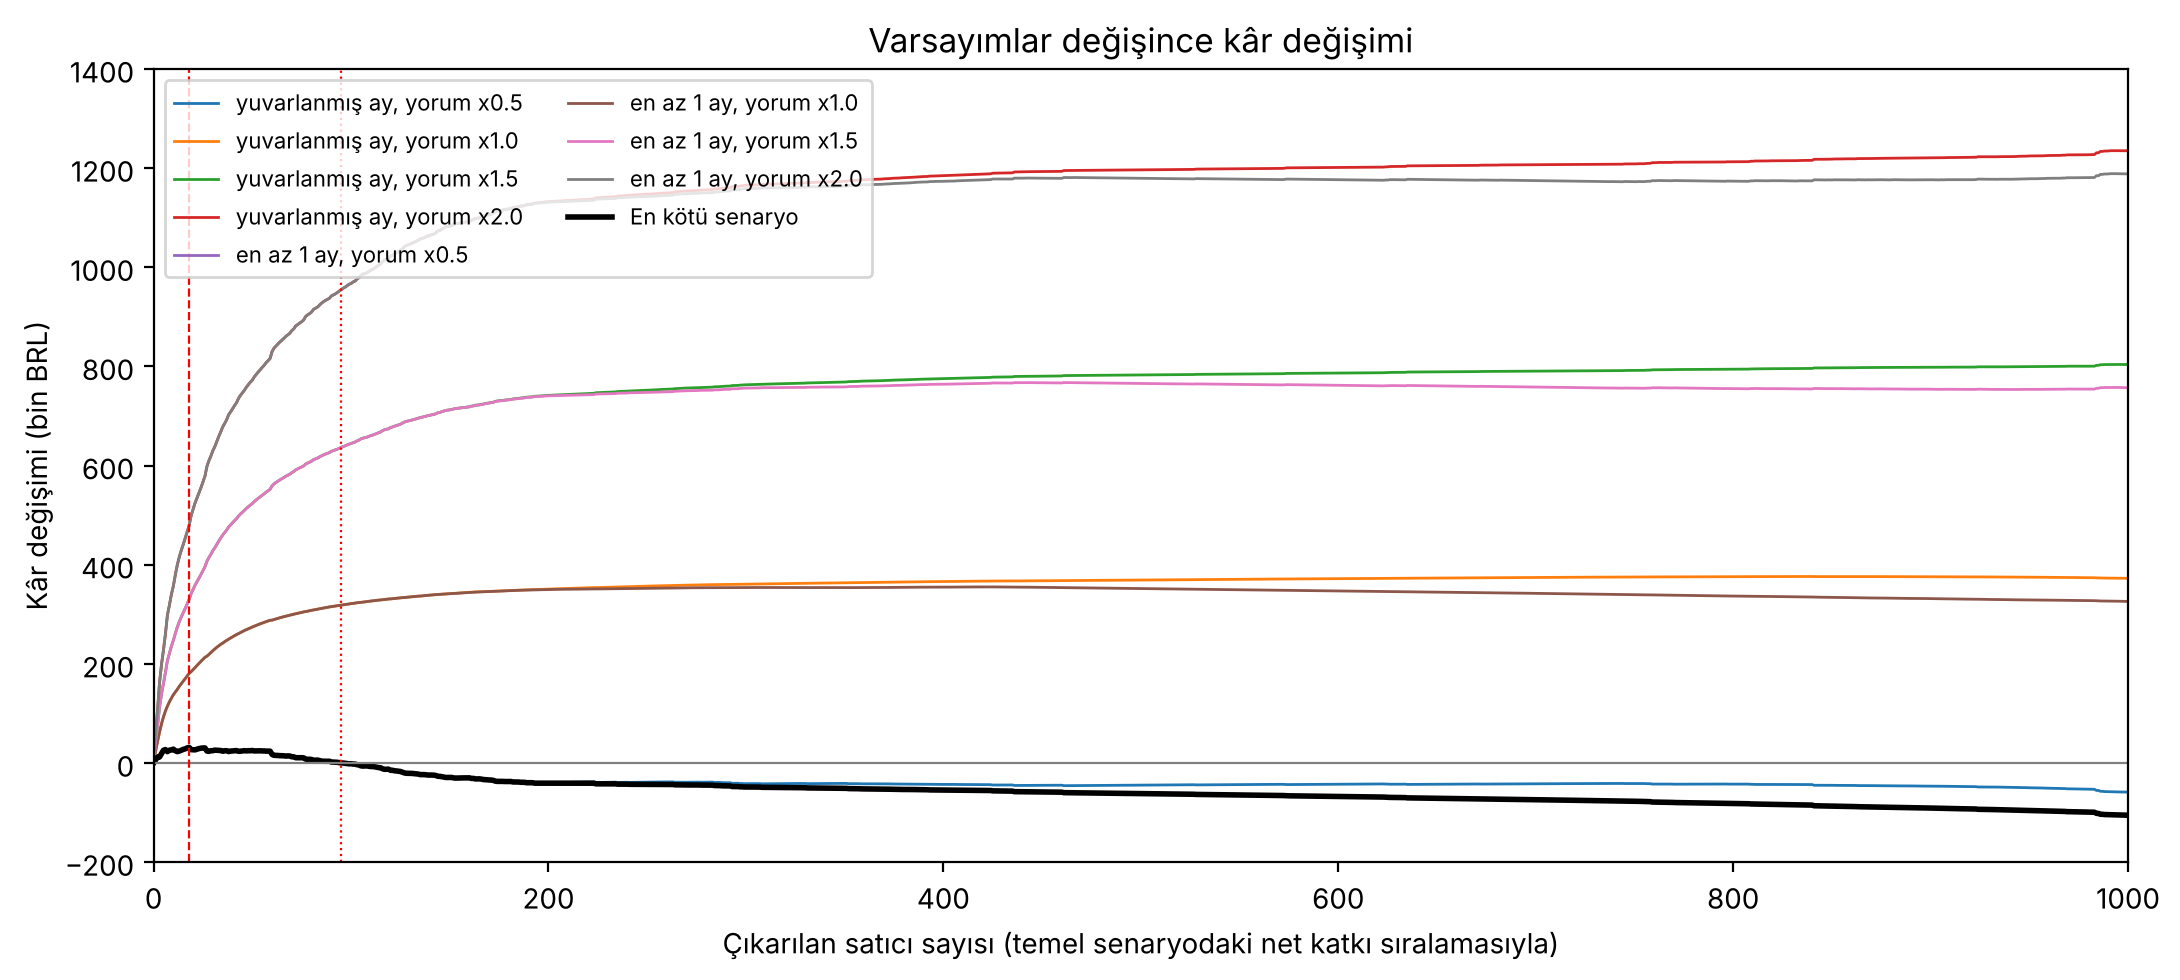

In [12]:
plt.figure(figsize=(11, 5))
for col in gains.columns:
    plt.plot(gains.index, gains[col] / 1e3, linewidth=1, label=col)
plt.plot(worst_case.index, worst_case / 1e3, color="black", linewidth=2, label="En kötü senaryo")
plt.axhline(0, color="gray", linewidth=0.8)
plt.axvline(robust_n, color="red", linewidth=0.8, linestyle="--")
plt.axvline(robust_limit, color="red", linewidth=0.8, linestyle=":")
plt.xlim(0, 1000)
plt.ylim(-200, 1400)
plt.xlabel("Çıkarılan satıcı sayısı (temel senaryodaki net katkı sıralamasıyla)")
plt.ylabel("Kâr değişimi (bin BRL)")
plt.title("Varsayımlar değişince kâr değişimi")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

In [13]:
sellers["grup"] = np.where(sellers["seller_id"].isin(ranking[:robust_n]), f"En kötü {robust_n}",
                  np.where(sellers["seller_id"].isin(ranking[:best_n]), f"{robust_n + 1}-{best_n}", "Kalan"))

sellers.groupby("grup").agg(
    satici=("seller_id", "count"),
    medyan_siparis=("n_orders", "median"),
    toplam_urun=("quantity", "sum"),
    medyan_ay=("months_on_olist", "median"),
    ort_puan=("review_score", "mean"),
    bir_yildiz_orani=("share_of_one_stars", "mean"),
    wait_time=("wait_time", "mean"),
    delay_to_carrier=("delay_to_carrier", "mean"),
    gelir=("revenues", "sum"),
    yorum_maliyeti=("cost_of_reviews", "sum"),
    net_katki=("net_contribution", "sum"),
).round(2)

,satici,medyan_siparis,toplam_urun,medyan_ay,ort_puan,bir_yildiz_orani,wait_time,delay_to_carrier,gelir,yorum_maliyeti,net_katki
grup,,,,,,,,,,,
19-840,822,2.0,34108,0.0,3.88,0.17,12.82,0.74,431729.14,540960.12,-256379.50
En kötü 18,18,827.5,18273,17.5,3.76,0.17,13.96,0.00,146020.25,298424.64,-206755.25
Kalan,2127,9.0,60060,6.0,4.19,0.10,11.86,0.25,2195563.64,704810.24,1192253.46


## Sonuç

- **CEO'ya cevap:** Verilen P&L varsayımlarıyla kârı en çok artıran seçenek, net katkısı en kötü **840 satıcıyı** çıkarmak. Bu durumda kâr (IT sonrası) 729 bin BRL'den 1.105 bin BRL'ye çıkıyor (**+376 bin BRL, +%52**). Ancak önerim, en kötü **18 satıcıdan başlamak**. Bu 18 satıcı, kâr artışının tek başına yarısını getiriyor (+181 bin BRL, +%25) ve denenen 8 varsayım senaryosunun hepsinde kârı artırıyor. Kapsam daha sonra en fazla **95 satıcıya** kadar genişletilebilir; o noktaya kadar kazanç her senaryoda pozitif kalıyor. 840 satıcıyı birden çıkarmak, kârı yalnızca iyimser varsayımlar altında artırıyor ve platform hacminin yarısını götürüyor.

- **P&L varsayımları:**
  - Gelir: teslim edilen siparişlerde ürün fiyatının %10'u satış komisyonu (kargo hariç) + satıcı başına ayda 80 BRL abonelik. Aboneliğin süresi `months_on_olist` = (son satış - ilk satış) / 30 gün, yuvarlanmış. Tek ayda satış yapan bir satıcı bu tanımla 0 ay sayılıyor ve abonelik ödemiyor (duyarlılık analizinde "en az 1 ay" alternatifi denendi).
  - Yorum maliyeti: 1 yıldız 100, 2 yıldız 50, 3 yıldız 40, 4-5 yıldız 0 BRL. Bir siparişte birden fazla yorum varsa ortalaması, birden fazla satıcı varsa maliyet ürün payına göre bölündü. Böylece maliyet satıcılara iki kez yazılmadı. İptal edilen siparişlerin yorum maliyeti de sayıldı, çünkü kötü deneyim onlarda da yaşanıyor.
  - IT maliyeti: 3157.27 × √(satıcı sayısı) + 978.23 × √(ürün sayısı). Bugünkü 2967 satıcı ve 112.441 ürünle 499.999 BRL, IT departmanının bildirdiği 500 bin BRL ile tutarlı. Satıcı sıralaması için bu toplam, satıcılara ortalama maliyet üzerinden dağıtıldı (satıcı başına 58 BRL + ürün başına 2.92 BRL). Senaryolarda ise IT maliyeti her N için kalan satıcı ve ürün sayısıyla formülden yeniden hesaplandı. Böylece ölçek etkisi korundu: ürün başına marjinal maliyet (1.46 BRL) ortalamanın yarısı.
  - Analizde 2967 satıcı var: teslim edilmiş siparişi ve yorumu olan satıcılar.

- **Bugünkü durum:** Gelir 2.77 milyon BRL (1.45 milyon abonelik + 1.32 milyon komisyon), yorum maliyeti 1.54 milyon, IT 0.50 milyon, kâr 0.73 milyon BRL. Sipariş başına ortalama yorum maliyeti (15.79 BRL) ortalama komisyondan (13.40 BRL) yüksek, yani ortalama bir sipariş komisyon olarak getirdiğinden fazla yorum maliyeti yaratıyor. Kârı abonelik taşıyor. 954 satıcının net katkısı negatif. En kötü 10 satıcının hepsi büyük ve uzun süredir platformda olan SP satıcıları (423-1854 sipariş). Puanları fena değil (3.5-4.1), ama hacimleri büyük olduğu için 1 yıldızlı yorumların toplam maliyeti komisyonlarını aşıyor.

- **Senaryo sonuçları (temel varsayımlar):**

| Çıkarılan | Kâr değişimi | Gelir kaybı | Ürün kaybı |
|---|---|---|---|
| 18 | +181 bin (+%25) | %5.3 | %16.3 |
| 50 | +274 bin (+%38) | %9.9 | %28.1 |
| 100 | +322 bin (+%44) | %14.2 | %36.1 |
| 383 (IT hariç optimum) | +365 bin (+%50) | %19.7 | %45.0 |
| 840 (IT dahil optimum) | +376 bin (+%52) | %20.8 | %46.6 |

  Kâr eğrisi ilk 100 satıcıda hızla yükseliyor, sonra neredeyse düzleşiyor: 100'den 840'a giderken kâr yalnızca 55 bin BRL daha artıyor, ama 740 satıcı daha kayboluyor. Kâr artışı 2320 satıcıya kadar pozitif kalıyor. IT maliyetleri optimumu 383'ten 840'a kaydırıyor (her satıcı yaklaşık 29 BRL marjinal IT maliyeti taşıyor), ama kâr değişimine etkisi küçük (365'e karşı 376 bin).

- **Duyarlılık:** Yorum maliyetleri tahmini olduğu için 0.5, 1, 1.5 ve 2 katı, abonelik için de iki ay tanımı denendi (8 senaryo). Senaryo optimumu 18 ile 1587 satıcı arasında değişiyor. Yorum maliyeti yarıya inerse optimum 18'e düşüyor ve 840 satıcıyı çıkarmak kârı azaltıyor (-43 ile -85 bin BRL). "En az 1 ay abonelik" tanımında optimum 424'e iniyor, çünkü 19-840 arasındaki satıcıların çoğu yeni ve tek aylık (medyan 2 sipariş, 0 ay). Bu satıcılar ancak abonelik ödemedikleri varsayılırsa zarar ettiriyor. En kötü 18 satıcıyı çıkarmak ise her senaryoda kârlı (+31.5 ile +479 bin BRL).

- **Çıkarılacak satıcıların profili:** En kötü 18 satıcı küçük ya da yeni değil, platformun en büyük satıcıları arasında: medyan 828 sipariş, 17.5 ay, toplam ürünlerin %16'sı. Ortalama puanları 3.76, 1 yıldız oranları %17 (kalan satıcılarda %10). Sorun ağırlıklı olarak teslimat değil (`delay_to_carrier` 0, `wait_time` 14.0 gün, diğerlerinde 11.9); yüksek hacimde kötü yorum biriktiriyorlar. Bu yüzden ilk adım doğrudan çıkarmak değil, bu 18 satıcıya ölçülebilir hedefli bir kalite planı vermek olmalı (ör. 1 yıldız oranını %10'a indirmek), hedef tutmazsa çıkarmak.

- **Sınırlılıklar:**
  - Analiz geriye dönük bir "bu satıcılar hiç olmasaydı" senaryosu. Gerçekte kimin kötü satıcı olacağı önceden bilinmiyor.
  - Çıkarılan satıcıların müşterilerinin tamamen kaybolduğu varsayıldı. Bir kısmı başka satıcılardan alırsa gelir kaybı daha küçük olur, ama o siparişlerin yorum maliyeti yeni satıcının kalitesine bağlı.
  - Sonuç en çok yorum maliyeti varsayımına bağlı; bu sayılar ölçülmüş değil, tahmin.
  - Satıcı çıkarmanın müşteri tabanı, ürün çeşitliliği ve uzun vadeli büyüme üzerindeki etkileri modelde yok.